# 03 · Stage 3: the auction panel (spec §6)

**Gate: the panel checks.**
1. Auction counts by financial year reconcile to the DMO (spot-check at least 5 years).
2. No duplicate (date, ISIN) pairs.
3. Every ISIN is matched to terms.
4. Linkers are excluded and the count is reported.

One extra check is added: the DMO's average accepted yield must reprice to its average accepted price, using our terms and the DMO settlement date.

**What Stage 3 delivers**
- `gilt_study.auctions`: readers for D2.1A, syndications, tenders, other operations and QT sales; `build_panel()`; `panel_checks()`.
- `data/processed_data/auctions/auction_panel.csv`: one row per conventional auction, 1 Nov 1998 – 30 Sep 2026.
- M1 and M2 are **not** computed here (Stage 4). The M2 control is still to be decided.

**Where each field comes from**

| Field | Source / rule |
|---|---|
| auction date, name, amounts, cash, cover, AAP, AAY, tail | D2.1A (D2.1E truncates prices and yields, so it is not used for them) |
| ISIN, **settlement date** | the auction's D2.1E row: the first *priced* row within 5 days after the auction, with the same coupon, maturity year and total nominal. Its issue date is the settlement date (spec §4) |
| maturity, first issue, first coupon (+ source, flags) | `gilt_terms` (Stage 1, P3–P4) |
| new issue / reopening | new issue = the auction settles on the gilt's first issue date |
| nominal offered / allotted | D2.1A "issued via auction". The DMO allots the full amount offered (checked against result notices, including the one uncovered auction) |
| PAOF take-up | D2.1A; 0 when blank from 1 Jun 2009; missing before (the facility did not exist) |
| yield at lowest accepted price | AAY + tail (D2.1A tail is the DMO definition, from unrounded yields) |
| years to maturity, bucket | from the settlement date; short < 7y, medium 7–15y, long > 15y (spec §6) |
| DV01 | `gilt_price()` DV01 at the AAY (dirty, per £100, per bp) × nominal / 100, for the auction allotment and for the total including the PAOF |
| T-1 curve, years beyond curve | Stage 2 panel; `curve.years_beyond_curve()` (decision #12); robustness drop if > 5 years |
| regime | spec §8 by auction date. Feb–Oct 2022 outside the LDI window is labelled *open* (spec §8 ⏳) |
| supply controls | syndications, tenders, QT sale days within ±5 UK business days (inclusive). Taps and mini-tender re-sales are recorded separately |
| rate volatility | **not defined in the spec**, so two candidates: std of 20 daily changes to T-1 in the BoE spot rate at 10y, and at the gilt's own maturity |

In [1]:
import datetime as dt
import warnings

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import seaborn as sns

from gilt_study import auctions as au, config, plotting

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 220); pd.set_option("display.max_rows", 120); pd.set_option("display.max_columns", 30)
plotting.set_seaborn_theme()

P = au.build_panel()            # ~20 s; writes data/processed_data/auctions/auction_panel.csv
C = au.panel_checks(P)
print(f"{len(P)} conventional auctions, {P.auction_date.min()} to {P.auction_date.max()}; {P.shape[1]} columns")
P.head(3).T

912 conventional auctions, 1999-05-26 to 2026-09-29; 69 columns


,0,1,2
auction_date,1999-05-26,1999-06-22,1999-09-28
settlement_date,1999-05-27,1999-06-23,1999-09-29
settlement_is_t_plus_1,True,True,True
financial_year,1999-00,1999-00,1999-00
regime,pre-crisis,pre-crisis,pre-crisis
gilt_name,6% Treasury Stock 2028,5% Treasury Stock 2004,5¾% Treasury Stock 2009
isin,GB0002404191,GB0006686579,GB0003042636
coupon,6.0,5.0,5.75
maturity,2028-12-07,2004-06-07,2009-12-07
first_issue,1998-01-29,1999-06-23,1998-07-30


## 1. Which auctions are in the panel, and which are excluded

In [2]:
A = au.load_d2_1a()
win = (A.auction_date >= config.STUDY_START) & (A.auction_date <= config.STUDY_END)
print(f"D2.1A outright auctions, all dates: {len(A)} ({(~A.index_linked).sum()} conventional, {A.index_linked.sum()} index-linked)")
print(f"in the window {config.STUDY_START} to {config.STUDY_END}: {win.sum()}")
print(f"  index-linked, excluded (check 4):      {C['linkers_in_window']}")
print(f"    of which a case-sensitive 'Index-linked' filter would miss: {C['linkers_missed_by_case_sensitive_filter']}")
print(f"  conventional, in the panel:            {C['conventional_in_window']}  (panel rows: {C['panel_rows']})")
conv = A[~A.index_linked]
print(f"conventional auctions outside the window: {int((conv.auction_date < config.STUDY_START).sum())} before 1 Nov 1998, "
      f"{int((conv.auction_date > config.STUDY_END).sum())} after Sep 2026")
A[win & A.index_linked & ~A.index_linked_case_sensitive][["auction_date", "gilt_name"]]

D2.1A outright auctions, all dates: 1244 (915 conventional, 329 index-linked)
in the window 1998-11-01 to 2026-09-30: 1240
  index-linked, excluded (check 4):      328
    of which a case-sensitive 'Index-linked' filter would miss: 5
  conventional, in the panel:            912  (panel rows: 912)
conventional auctions outside the window: 2 before 1 Nov 1998, 1 after Sep 2026


,auction_date,gilt_name
653,2018-03-27,0 1/8% Index-Linked Treasury Gilt 2056
677,2018-11-20,0 1/8% Index-Linked Treasury Gilt 2056
813,2020-09-02,0 1/8% Index-Linked Treasury Gilt 2056
882,2021-03-24,0 1/8% Index-Linked Treasury Gilt 2056
924,2021-09-22,0 1/8% Index-Linked Treasury Gilt 2056


## 2. ISIN and settlement date from D2.1E

In [3]:
print("auctions with exactly one candidate ISIN:", int((P.d2_1e_candidate_isins == 1).sum()), "of", len(P))
print("settlement date (DMO issue date) = auction date + 1 UK business day:", int(P.settlement_is_t_plus_1.sum()), "of", len(P))
print("D2.1E nominal = D2.1A total (auction + PAOF):", int(P.d2_1e_nominal_matches.sum()), "of", len(P))
C["d2_1e_nominal_differences"]

auctions with exactly one candidate ISIN: 912 of 912
settlement date (DMO issue date) = auction date + 1 UK business day: 912 of 912
D2.1E nominal = D2.1A total (auction + PAOF): 905 of 912


,auction_date,gilt_name,nominal_total,d2_1e_nominal,d2_1e_minus_d2_1a_nominal
0,1999-05-26,6% Treasury Stock 2028,2480.0,2500.0,20.0
1,1999-06-22,5% Treasury Stock 2004,2480.0,2500.0,20.0
2,1999-09-28,5¾% Treasury Stock 2009,2730.0,2750.0,20.0
7,2001-05-24,5% Treasury Stock 2012,2500.0,2525.0,25.0
10,2002-03-27,5% Treasury Stock 2012,2250.0,2300.0,50.0
12,2002-06-25,5% Treasury Stock 2008,3000.0,3050.0,50.0
13,2002-07-24,5% Treasury Stock 2014,2750.0,2800.0,50.0


**Reading it.**
- Every auction ties to exactly one ISIN.
- Every settlement date taken from the DMO is T+1, so the spec §4 rule changes no date in this sample. It still guards against holidays and against a mis-assumed lag.
- Seven early auctions (1999–2002) show **£20–50m more in D2.1E than in D2.1A**. This is consistent with D2.1A note 2: purchases by the CRND (Commissioners for the Reduction of the National Debt) are made at the AAP and do not count as financing. *Not verified beyond the note.* The panel uses D2.1A's amounts.

## 3. Check 1: counts by financial year against the DMO

- **All auctions** (conventional + index-linked) per financial year come from the DMO Gilt Market Annual Review 2023-24, Table 9, every year from 1998-99 to 2023-24.
- **Conventional auctions by bucket** come from the Annual Reviews for 2016-17, 2017-18, 2020-21 and 2023-24 (outturns), and the 2009-10 remit plan; the 2009-10 outturn total, 58, equals the plan. Sources are in SOURCES.md #5b.

In [4]:
print(C["fy_all_auctions"].to_string())
print(f"\nall {len(C['fy_all_auctions'])} years match: {bool(C['fy_all_auctions']['match'].all())}")
C["fy_buckets"].drop(columns="source")

         dmo_all_auctions  d2_1a_all_auctions  d2_1a_conventional  d2_1a_index_linked  match  dmo_figure_uncertain
1998-99                 4                   4                   2                   2   True                  True
1999-00                 8                   8                   4                   4   True                 False
2000-01                 7                   7                   3                   4   True                 False
2001-02                 8                   8                   4                   4   True                 False
2002-03                13                  13                   8                   5   True                 False
2003-04                24                  24                  16                   8   True                 False
2004-05                26                  26                  16                  10   True                 False
2005-06                25                  25                  15               

,dmo_short,ours_short,dmo_medium,ours_medium,dmo_long,ours_long,dmo_index_linked,ours_index_linked,match
financial_year,,,,,,,,,
2009-10,15,15,19,19,12,12,12,12,True
2016-17,13,13,11,11,12,12,12,12,True
2017-18,10,10,9,9,10,10,11,11,True
2020-21,46,46,39,39,46,46,19,19,True
2023-24,20,20,20,20,15,15,14,14,True


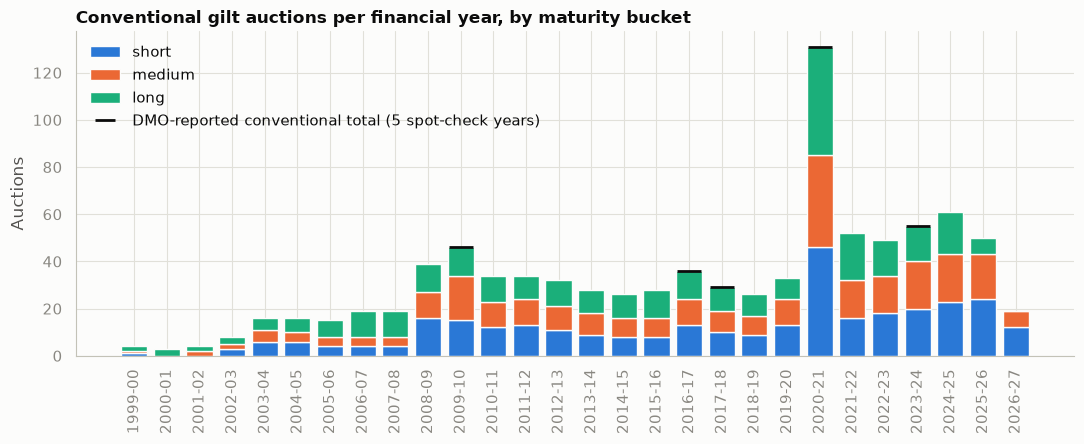

In [5]:
fy = P.groupby(["financial_year", "bucket"]).size().unstack(fill_value=0)[["short", "medium", "long"]]
cmap = plotting.colour_map(["short", "medium", "long"])
title = "Conventional gilt auctions per financial year, by maturity bucket"

fig_s, ax = plt.subplots(figsize=(11, 4.6))
bottom = np.zeros(len(fy))
for b in ["short", "medium", "long"]:
    ax.bar(range(len(fy)), fy[b], bottom=bottom, color=cmap[b], label=b, width=0.8,
           edgecolor=plotting.SURFACE, linewidth=1)
    bottom += fy[b].to_numpy()
for fyl, ((s, m, l, il), _) in au.DMO_BUCKET_COUNTS.items():
    i = list(fy.index).index(fyl)
    ax.scatter(i, s + m + l, marker="_", s=300, color=plotting.INK, zorder=4)
ax.set_xticks(range(len(fy)), fy.index, rotation=90)
ax.set_ylabel("Auctions")
ax.set_title(title)
from matplotlib.lines import Line2D
handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([], [], marker="_", markersize=14, markeredgewidth=2, color=plotting.INK, linestyle="none"))
labels.append("DMO-reported conventional total (5 spot-check years)")
ax.legend(handles, labels, title=None, loc="upper left")
fig_s.tight_layout()

fig_p = go.Figure()
for b in ["short", "medium", "long"]:
    fig_p.add_trace(go.Bar(x=fy.index, y=fy[b], name=b, marker_color=cmap[b],
                           marker_line=dict(color=plotting.SURFACE, width=1),
                           hovertemplate="%{x}<br>" + b + ": %{y} auctions<extra></extra>"))
chk = [(k, sum(v[0][:3])) for k, v in au.DMO_BUCKET_COUNTS.items()]
fig_p.add_trace(go.Scatter(x=[k for k, _ in chk], y=[v for _, v in chk], mode="markers", name="DMO-reported total",
                           marker=dict(symbol="line-ew-open", size=18, color=plotting.INK, line=dict(width=2)),
                           hovertemplate="%{x}<br>DMO: %{y} conventional auctions<extra></extra>"))
fig_p.update_layout(template=plotting.PLOTLY_TEMPLATE, barmode="stack", bargap=0.2, height=460, title=title,
                    yaxis_title="Auctions", legend=dict(orientation="h", y=-0.25))
plotting.save_pair("auction_counts_by_fy", fig_s, fig_p)
fig_p.show()

**Result.**
- **All 26 financial years match** the DMO's total auction count exactly. The 1998-99 DMO figure was read from the table layout, not a labelled cell, so it is marked uncertain; it matches anyway.
- **All 5 spot-check years match by bucket**, including the index-linked count.
- So the bucket rule (years to maturity at settlement; short < 7, medium 7–15, long > 15) reproduces the DMO's own classification in those years.
- 2020-21 (Covid remit, 131 conventional auctions) is the largest year.

## 4. Checks 2–3: duplicates and terms

In [6]:
for k in ["duplicates", "isin_missing", "terms_missing", "ambiguous_isin"]:
    print(f"{k:16s} {C[k]}")
print("\nmaturity source:", P.maturity_source.value_counts().to_dict())
print("first issue source:", P.first_issue_source.value_counts().to_dict())

duplicates       0
isin_missing     0
terms_missing    0
ambiguous_isin   0

maturity source: {'D1A': 556, 'D1C (coupon + year)': 356}
first issue source: {'D1A': 556, 'D2.1E launch row': 356}


## 5. Extra check: the DMO's AAY reprices to its AAP

Each auction's average accepted yield is priced with our terms (first issue and first coupon dates) for the DMO settlement date. The result is then compared with the published average accepted price. This tests settlement, first issue and first coupon together on every auction, including the post-2017 gilts whose first coupon comes from the flagged rule. It is a clean-price test: an AAP rounded to 2 dp (3 dp from 2014) allows an error of half a unit.

In [7]:
print(C["aap_check_counts"].to_string())
late = P[pd.to_datetime(P.auction_date) >= "2003-07-29"]
print(f"\nfrom 29 Jul 2003: max |error| {late.loc[late.aay_decimals > 3, 'aap_check_error'].abs().max():.2e} "
      f"(AAY given to 4+ dp, {int((late.aay_decimals > 3).sum())} auctions); AAY given to 3 dp only: "
      f"{late.loc[late.aay_decimals <= 3, ['auction_date', 'gilt_name', 'aay', 'aap_check_error']].to_dict('records')}")
fr = P[P.flag_first_coupon_rule]
print(f"auctions priced with a rule-based first coupon (rule date still ahead): {len(fr)}; "
      f"AAP check 'rounded': {(fr.aap_check == 'rounded').sum()}; max |error| {fr.aap_check_error.abs().max():.2e}")
C["aap_check_not_rounded"]

aap_check
rounded      903
truncated      9

from 29 Jul 2003: max |error| 2.19e-05 (AAY given to 4+ dp, 883 auctions); AAY given to 3 dp only: [{'auction_date': datetime.date(2009, 3, 4), 'gilt_name': '4¼% Treasury Gilt 2039', 'aay': 4.485, 'aap_check_error': -0.00575524061015642}, {'auction_date': datetime.date(2011, 2, 1), 'gilt_name': '2% Treasury Gilt 2016', 'aay': 2.701, 'aap_check_error': 1.4209343675020136e-06}, {'auction_date': datetime.date(2017, 10, 19), 'gilt_name': '1¼% Treasury Gilt 2027', 'aay': 1.317, 'aap_check_error': 4.033025817307134e-06}, {'auction_date': datetime.date(2020, 11, 12), 'gilt_name': '1 5/8% Treasury Gilt 2054', 'aay': 0.972, 'aap_check_error': -8.029377696061601e-06}]
auctions priced with a rule-based first coupon (rule date still ahead): 89; AAP check 'rounded': 89; max |error| 9.99e-06


,auction_date,gilt_name,aap,aay,clean_at_aay,aap_check_error,aap_check
0,1999-05-26,6% Treasury Stock 2028,120.59,4.702711,120.596939,0.006939,truncated
1,1999-06-22,5% Treasury Stock 2004,98.79,5.279205,98.798796,0.008796,truncated
2,1999-09-28,5¾% Treasury Stock 2009,100.41,5.693905,100.419667,0.009667,truncated
3,1999-11-24,6% Treasury Stock 2028,128.95,4.253706,128.955772,0.005772,truncated
7,2001-05-24,5% Treasury Stock 2012,98.81,5.144870,98.819898,0.009898,truncated
11,2002-05-29,5% Treasury Stock 2025,97.62,5.178042,97.627127,0.007127,truncated
14,2002-10-22,5% Treasury Stock 2014,102.05,4.770323,102.058180,0.008180,truncated
18,2003-03-26,5% Treasury Stock 2008,103.63,4.178028,103.636090,0.006090,truncated
22,2003-06-12,5% Treasury Stock 2014,107.98,4.104611,107.987711,0.007711,truncated


**Result: every auction reprices.**
- From **29 Jul 2003** the AAY reprices to the AAP within about 2e-5 of a pound. The one exception is 4 Mar 2009, whose AAY is given only to 3 dp; the rounding of that yield is allowed for.
- **Before Jul 2003** all 32 auctions show a non-negative error below 0.01. This pattern means the AAY was computed from the *unrounded* AAP, and the published AAP was **truncated** to 2 dp. For 9 of them the error exceeds half a unit, so they pass only on that reading. The AAY is what M1 uses, so this affects nothing downstream.
- **The 89 auctions priced with a rule-based first coupon** all reprice within about 1e-5. For a new gilt, a wrong first coupon would move the price by tenths of a pound. So the DMO's own auction yields **confirm the rule's dates** for every post-2017 gilt the rule covers.

Two DMO result notices also match the panel field by field (`tests/test_auctions.py`):
- **25 Mar 2009, 4¼% 2049** (the uncovered auction): offered and allotted £1,750m, cover 0.93, AAP 95.24, AAY 4.506%, lowest accepted yield 4.634%, tail 12.8bp.
- **10 Aug 2010, 4½% 2034:** £1,750m, cover 1.56, AAP 104.51, AAY 4.200%, lowest accepted yield 4.203%, tail 0.3bp.

## 6. The fields at a glance

In [8]:
print("new issues vs reopenings:\n", pd.crosstab(P.new_issue, P.bucket, margins=True), "\n")
print("first coupon priced with the flagged rule (rule date still ahead at the auction):", int(P.flag_first_coupon_rule.sum()),
      "| gilts whose first coupon came from the rule, all auctions:", int(P.gilt_first_coupon_from_rule.sum()),
      "| manual-check:", int(P.flag_first_coupon_manual_check.sum()))
print("\nregime:\n", P.regime.value_counts().to_string())
print("\nPAOF take-up > 0:", int((P.paof_takeup > 0).sum()), "of", int(P.paof_takeup.notna().sum()), "auctions since 1 Jun 2009")
P[["nominal_offered", "paof_takeup", "bid_to_cover", "aay", "tail_bp", "years_to_maturity", "dv01_per_100",
   "dv01_gbp_per_bp_auction", "dv01_gbp_per_bp_total", "vol_10y_20d_bp", "vol_own_maturity_20d_bp"]].describe().round(3).T

new issues vs reopenings:
 bucket     long  medium  short  All
new_issue                          
False       284     262    286  832
True         15      27     38   80
All         299     289    324  912 

first coupon priced with the flagged rule (rule date still ahead at the auction): 89 | gilts whose first coupon came from the rule, all auctions: 287 | manual-check: 0

regime:
 regime
QE                     546
active QT              208
pre-crisis             129
Feb-Oct 2022 (open)     24
LDI stress               3
post-QT-decision         2

PAOF take-up > 0: 495 of 761 auctions since 1 Jun 2009


,count,mean,std,min,25%,50%,75%,max
nominal_offered,912.0,2912.763,873.667,1000.000,2250.000,2750.000,3500.000,5250.000
paof_takeup,761.0,276.677,300.724,0.000,0.000,211.090,421.476,1249.999
bid_to_cover,912.0,2.281,0.575,0.930,1.840,2.220,2.640,3.940
aay,912.0,2.705,1.680,-0.088,1.115,2.851,4.283,5.790
tail_bp,912.0,0.558,0.765,-5.500,0.200,0.400,0.700,12.800
years_to_maturity,912.0,14.592,11.813,1.895,5.305,9.952,21.614,53.366
dv01_per_100,912.0,0.110,0.082,0.018,0.051,0.086,0.151,0.527
dv01_gbp_per_bp_auction,912.0,2679547.373,1198621.483,611068.049,1786054.486,2530305.280,3345368.940,6599238.753
dv01_gbp_per_bp_total,912.0,2901052.868,1343124.251,658209.171,1916298.668,2675119.300,3703804.739,7583741.025
vol_10y_20d_bp,912.0,5.027,2.187,2.053,3.547,4.506,5.985,19.821


### Years beyond the curve (decision #12)

beyond_curve                  False  True       All
drop_extrapolation_robustness False False True     
era                                                
before 2016 (curve to 25y)      276    21   67  364
from 2016 (curve to 40y)        535     5    8  548
All                             811    26   75  912


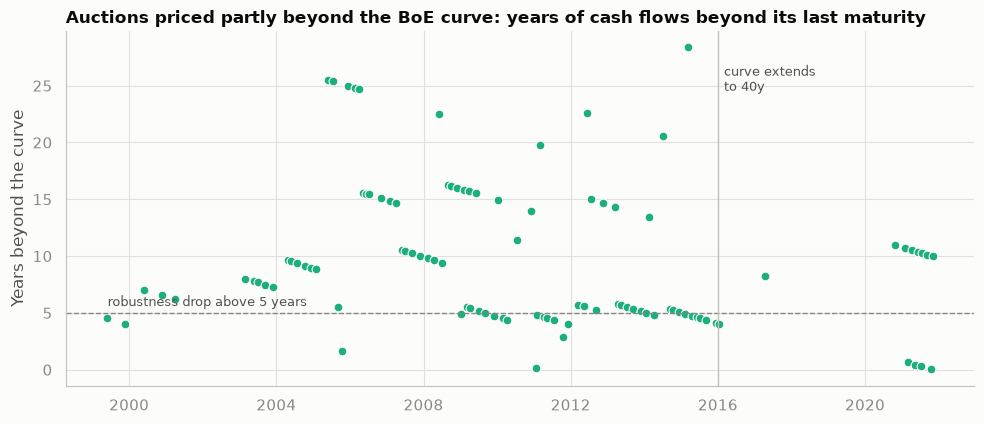

In [9]:
P["era"] = np.where(pd.to_datetime(P.auction_date) < "2016-01-01", "before 2016 (curve to 25y)", "from 2016 (curve to 40y)")
print(pd.crosstab(P.era, [P.beyond_curve, P.drop_extrapolation_robustness], margins=True))
E = P[P.beyond_curve].copy()
E["auction_ts"] = pd.to_datetime(E.auction_date)
cm = plotting.colour_map(["short", "medium", "long"])
title = "Auctions priced partly beyond the BoE curve: years of cash flows beyond its last maturity"

fig_s, ax = plt.subplots(figsize=(10, 4.4))
ax.axhline(config.MAX_YEARS_BEYOND_CURVE, color=plotting.INK_MUTED, lw=1, ls="--")
ax.text(pd.Timestamp("1999-06-01"), config.MAX_YEARS_BEYOND_CURVE + 0.6, "robustness drop above 5 years",
        color=plotting.INK_SECONDARY, fontsize=9)
ax.scatter(E.auction_ts, E.years_beyond_curve, s=40, color=cm["long"], edgecolor=plotting.SURFACE, linewidth=0.8)
ax.axvline(pd.Timestamp("2016-01-01"), color=plotting.BASELINE, lw=1)
ax.text(pd.Timestamp("2016-03-01"), E.years_beyond_curve.max() * 0.95, "curve extends\nto 40y", fontsize=9,
        color=plotting.INK_SECONDARY, va="top")
ax.set_ylabel("Years beyond the curve")
ax.set_title(title)
fig_s.tight_layout()

fig_p = go.Figure()
fig_p.add_hline(y=config.MAX_YEARS_BEYOND_CURVE, line_dash="dash", line_color=plotting.INK_MUTED,
                annotation_text="robustness drop above 5 years", annotation_position="top left")
fig_p.add_vline(x=pd.Timestamp("2016-01-01").timestamp() * 1000, line_color=plotting.BASELINE)
fig_p.add_trace(go.Scatter(x=E.auction_ts, y=E.years_beyond_curve, mode="markers", name="auction",
                           marker=dict(color=cm["long"], size=9, line=dict(color=plotting.SURFACE, width=1)),
                           customdata=np.stack([E.gilt_name, E.years_to_maturity, E.curve_t_max], axis=1),
                           hovertemplate="%{customdata[0]}<br>%{x|%d %b %Y}<br>%{customdata[1]:.1f}y to maturity, "
                                         "curve to %{customdata[2]:.0f}y<br>%{y:.1f}y beyond<extra></extra>"))
fig_p.update_layout(template=plotting.PLOTLY_TEMPLATE, height=420, title=title, yaxis_title="Years beyond the curve",
                    showlegend=False)
plotting.save_pair("auction_years_beyond_curve", fig_s, fig_p)
fig_p.show()

- **101 auctions** are priced partly on the flat-forward extrapolation: 88 before 2016 and 13 ultra-longs from 2016.
- **75** have more than 5 years beyond the curve and are dropped in the robustness check (67 before 2016, 8 after). All are long-bucket auctions.

### Auction size in rate risk (DV01)

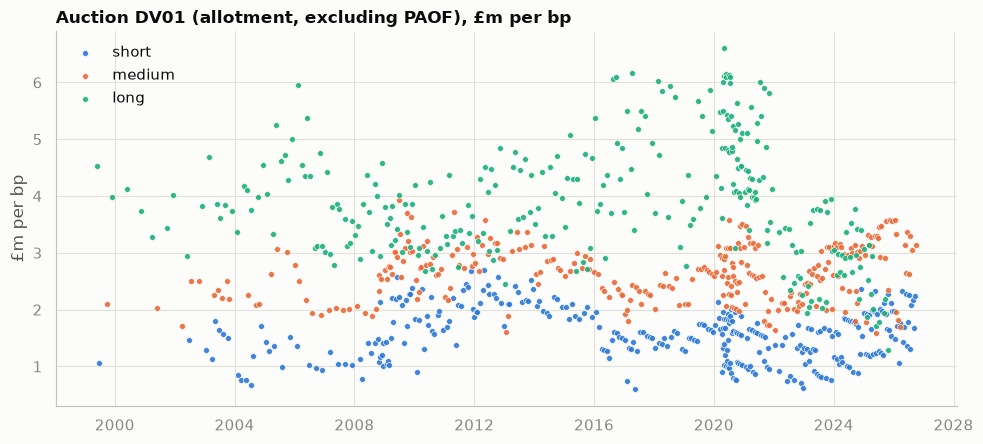

In [10]:
P["auction_ts"] = pd.to_datetime(P.auction_date)
title = "Auction DV01 (allotment, excluding PAOF), £m per bp"
fig_s, ax = plt.subplots(figsize=(10, 4.6))
for b in ["short", "medium", "long"]:
    s = P[P.bucket == b]
    ax.scatter(s.auction_ts, s.dv01_gbp_per_bp_auction / 1e6, s=18, color=cm[b], label=b,
               edgecolor=plotting.SURFACE, linewidth=0.5, alpha=0.9)
ax.set_ylabel("£m per bp")
ax.set_title(title)
ax.legend(title=None, loc="upper left")
fig_s.tight_layout()

fig_p = go.Figure()
for b in ["short", "medium", "long"]:
    s = P[P.bucket == b]
    fig_p.add_trace(go.Scatter(x=s.auction_ts, y=s.dv01_gbp_per_bp_auction / 1e6, mode="markers", name=b,
                               marker=dict(color=cm[b], size=8, line=dict(color=plotting.SURFACE, width=1)),
                               customdata=np.stack([s.gilt_name, s.nominal_auction, s.dv01_per_100], axis=1),
                               hovertemplate="%{customdata[0]}<br>%{x|%d %b %Y}<br>£%{customdata[1]:,.0f}m nominal, "
                                             "DV01 %{customdata[2]:.3f} per £100<br>%{y:.2f} £m/bp<extra></extra>"))
fig_p.update_layout(template=plotting.PLOTLY_TEMPLATE, height=440, title=title, yaxis_title="£m per bp",
                    legend=dict(orientation="h", y=-0.2))
plotting.save_pair("auction_dv01_over_time", fig_s, fig_p)
fig_p.show()

### Supply controls and rate volatility

In [11]:
sc = [c for c in P.columns if c.endswith("_pm5bd")]
print("auctions with at least one operation within ±5 business days:")
print(P[[c for c in sc if c.endswith(("_n_pm5bd", "_days_pm5bd"))]].gt(0).sum().to_string())
print("\ncorrelation of the two volatility candidates:", round(P[["vol_10y_20d_bp", "vol_own_maturity_20d_bp"]].corr().iloc[0, 1], 3))
P.groupby("bucket")[["vol_10y_20d_bp", "vol_own_maturity_20d_bp"]].median().round(2)

auctions with at least one operation within ±5 business days:
synd_n_pm5bd            210
synd_conv_n_pm5bd       121
tender_n_pm5bd          147
tender_conv_n_pm5bd     106
qt_sale_days_pm5bd      157
other_supply_n_pm5bd      2

correlation of the two volatility candidates: 0.896


,vol_10y_20d_bp,vol_own_maturity_20d_bp
bucket,,
long,4.40,4.14
medium,4.56,4.56
short,4.53,4.18


## 7. Data issue found

**4 Mar 2009, 4¼% Treasury Gilt 2039.** D2.1A gives a tail of **−5.5bp**. In a multiple-price auction the tail (yield at the lowest accepted price minus the AAY) cannot be negative. The AAY is also published only to 3 dp (4.485%). That day's DMO close was 4.589%, up from 4.384% the day before.

The panel keeps D2.1A's value and flags it (`flag_tail_negative`). The DMO result notice could not be found online to check the sign.

In [12]:
C["tail_negative"]

,auction_date,gilt_name,aay,tail_bp
139,2009-03-04,4¼% Treasury Gilt 2039,4.485,-5.5


## 8. Stopping here: the Stage 3 gate

**Panel checks:**
- FY counts: 26 of 26 years match; buckets: 5 of 5 years match.
- 0 duplicates.
- All 912 ISINs matched to terms.
- 328 linkers excluded, 5 of which a case-sensitive filter would miss.
- All 912 AAYs reprice to the AAP.

**Decisions for you** (each has a default in the panel; nothing downstream uses them yet):
1. **Rate volatility** (spec §6 does not define it). Candidates: realised volatility of the BoE spot rate over 20 days to T-1, at 10y, or at the gilt's own maturity. Or something else?
2. **Auction DV01 nominal.** Use the auction allotment (known before bidding closes) or the total including the PAOF (decided after the result, so partly an outcome)? Both are in the panel.
3. **Feb–Oct 2022** (24 auctions, outside the LDI window): spec §8 ⏳. They are labelled `Feb-Oct 2022 (open)`.
4. **Negative tail on 4 Mar 2009**: keep as published, set the tail to missing, or drop that auction from tail-based regressions?
5. **Supply controls.** Do syndications and tenders count linker operations too? Both versions are in the panel; spec §6 does not say. Should QE purchases also be a control (data #10, not listed in §6)?